# 🏛️ Clase 4 · Caso real: Triage inteligente de PQRS con Transformers

**Módulo:** Científico de Datos e Inteligencia Artificial Aplicada · **Unidad 2:** NLP y el Auge de la IA Generativa (LLMs)

---
## 📌 El problema (real)

**ServiRed S.A. E.S.P.** (empresa ficticia de energía e internet, problema 100 % real) recibe **~3.000 PQRS al mes**
(Peticiones, Quejas, Reclamos, Sugerencias, Denuncias) por web, correo, app y teléfono.

- 👥 **4 analistas** leen cada mensaje, deciden el **tipo**, el **área** responsable y la **urgencia**.
- ⏱️ Cada lectura + clasificación toma ~6 min → **300 horas/mes** solo en clasificar.
- ⚖️ **Ley 142 de 1994 (art. 158):** la empresa tiene **15 días hábiles** para responder. Si no lo hace,
  opera el **silencio administrativo positivo**: se entiende que **el usuario tiene la razón**.
- 🚨 Los casos graves (una persona con oxígeno sin luz, un poste a punto de caer) se pierden entre sugerencias y felicitaciones.
- 🔁 Cuando hay un daño masivo, llegan 200 mensajes del mismo problema y cada uno se trata por separado.

## 🎯 Lo que vamos a construir
```
PQRS ─► [Transformer] entiende el texto
          ├─ ¿Qué TIPO es?            (zero-shot NLI)
          ├─ ¿Qué ÁREA lo atiende?    (zero-shot NLI)
          ├─ ¿Qué tan URGENTE es?     (sentimiento + señales de riesgo)
          ├─ ¿Quién, dónde, cuánto?   (NER + regex) ─► anonimizar datos personales
          ├─ ¿Es un caso MASIVO?      (embeddings + clustering)
          ├─ ¿POR QUÉ decidió eso?    (explicabilidad por oclusión)
          └─ Borrador de respuesta    (LLM con los datos extraídos)
       ─► Bandeja priorizada con fecha límite legal ─► el analista revisa y aprueba (humano en el loop)
```

### ⏱️ Agenda
| Bloque | Tema |
|---|---|
| 1 | ¿Por qué no basta con reglas (`if "queja" in texto`)? |
| 2 | **¿Cómo "lee" un Transformer?** tokens, embeddings contextuales, atención, decisión |
| 3 | La solución paso a paso (tipo, área, urgencia, entidades, masivos, explicabilidad, respuesta) |
| 4 | Bandeja priorizada, impacto y riesgos |

---
## 0. Preparación

In [1]:
import importlib.util, subprocess, sys
paquetes = {"torch": "torch", "transformers": "transformers>=4.51", "sentence_transformers": "sentence-transformers",
            "sklearn": "scikit-learn", "pandas": "pandas", "matplotlib": "matplotlib", "accelerate": "accelerate"}
faltan = [p for m, p in paquetes.items() if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
print("✓ Entorno listo" + (f" (instalado: {faltan})" if faltan else ""))

✓ Entorno listo (instalado: ['torch', 'transformers>=4.51', 'sentence-transformers', 'scikit-learn', 'pandas', 'matplotlib', 'accelerate'])


In [2]:
import html, re, time, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from IPython.display import HTML, display
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from transformers import AutoModel, AutoModelForCausalLM, AutoTokenizer, pipeline

warnings.filterwarnings("ignore"); transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 140)
torch.manual_seed(42); np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODELO_BETO = "dccuchile/bert-base-spanish-wwm-cased"            # para "abrir" el Transformer
MODELO_ZS   = "Recognai/bert-base-spanish-wwm-cased-xnli"        # zero-shot (NLI)
MODELO_SENT = "pysentimiento/robertuito-sentiment-analysis"      # sentimiento
MODELO_NER  = "mrm8488/bert-spanish-cased-finetuned-ner"         # entidades
MODELO_EMB  = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODELO_LLM  = "Qwen/Qwen3-0.6B"                                  # borradores de respuesta
GENERAR_RESPUESTAS = True                                        # False si no hay tiempo/memoria

pqrs = pd.read_csv(Path("..") / "datasets" / "pqrs_servired.csv", parse_dates=["fecha"])
print(device, "|", len(pqrs), "PQRS"); pqrs.sample(6, random_state=1)

c:\Users\juand\Github\M6-Cientifico-Datos-IA-Aplicada-DevSeniorCode\Unidad 2\clase_04_caso_real_pqrs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cpu | 38 PQRS


,radicado,fecha,canal,texto,tipo,area,urgencia
2,PQR-2026-0003,2026-11-04,web,Quisiera saber qué documentos necesito para cambiar el titular del servicio a nombre de mi esposa.,peticion,atencion_cliente,baja
29,PQR-2026-0030,2026-11-17,app,La factura debería mostrar el consumo de los últimos 12 meses en una gráfica más clara.,sugerencia,facturacion,baja
3,PQR-2026-0004,2026-11-04,app,"Sería bueno que la app permitiera pagar con Nequi, así no tendría que ir a un punto físico.",sugerencia,atencion_cliente,baja
22,PQR-2026-0023,2026-11-12,telefono,"Me prometieron una visita técnica para el jueves y nunca llegaron, perdí el día de trabajo esperando.",queja,atencion_cliente,media
25,PQR-2026-0026,2026-11-12,web,"Hoy no hay internet en Chapinero Alto, necesito saber cuándo vuelve.",queja,tecnica,media
27,PQR-2026-0028,2026-11-13,web,"Solicito un acuerdo de pago para la deuda de $860.000, puedo pagar en 6 cuotas.",peticion,facturacion,baja


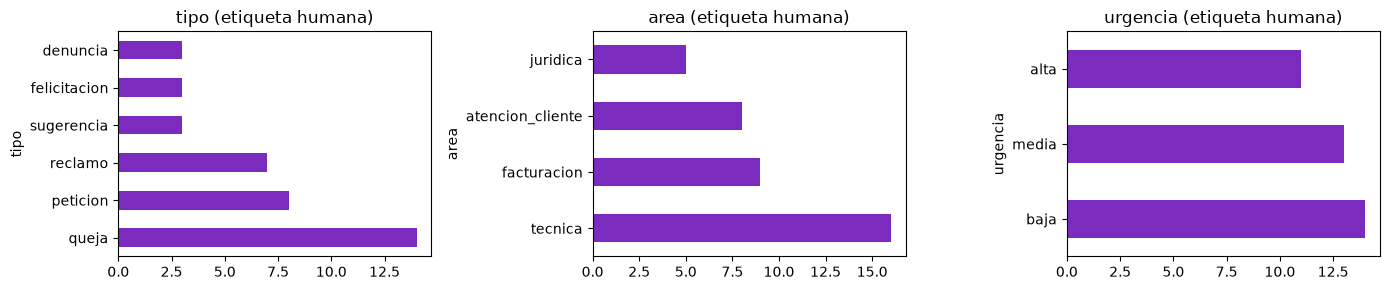

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, col in zip(ax, ["tipo", "area", "urgencia"]):
    pqrs[col].value_counts().plot.barh(ax=a, color="#7B2CBF", title=f"{col} (etiqueta humana)")
plt.tight_layout(); plt.show()

---
## 1. ¿Por qué no basta con reglas?
La primera idea de cualquier equipo: palabras clave. Probemos.

In [5]:
# ✍️ LIVE CODING — 1.1 Clasificador de tipo con reglas (palabras clave)
REGLAS = {
    "queja": ["queja", "reclamo", "insatisfacción", "mal servicio", "mala atención", "defecto", "error", "problema"],
    "sugerencia": ["sugerencia", "mejora", "propuesta", "idea", "recomendación", "optimización", "innovación","peticion", "solicitud", "consulta", "pregunta", "duda"],
    "denuncia": ["denuncia", "infracción", "violación", "ilegal", "ilegalidad", "delito", "fraude", "corrupción"],
    "felicitaciones": ["felicitación", "agradecimiento", "reconocimiento", "elogio", "aprecio", "gratitud", "satisfacción"]
}

def tipo_por_reglas(texto):
    texto = texto.lower()
    for tipo, palabras in REGLAS.items():
        if any(palabra in texto for palabra in palabras):
            return tipo
    return "peticion"

pqrs["tipo_reglas"] = pqrs["texto"].apply(tipo_por_reglas)
print(f"Exactitud con reglas: {accuracy_score(pqrs.tipo, pqrs.tipo_reglas):.0%}")
pqrs.loc[pqrs.tipo != pqrs.tipo_reglas, ["texto", "tipo", "tipo_reglas"]].head(8)

Exactitud con reglas: 21%


,texto,tipo,tipo_reglas
0,"Desde el lunes no tenemos luz en el barrio Kennedy, en mi casa vive mi mamá que usa oxígeno y nadie nos da respuesta. Exijo solución inm...",queja,peticion
1,Me llegó la factura de octubre por $480.000 cuando siempre pago alrededor de $120.000. Solicito revisión del medidor y reliquidación. Cé...,reclamo,peticion
3,"Sería bueno que la app permitiera pagar con Nequi, así no tendría que ir a un punto físico.",sugerencia,peticion
4,"Quiero felicitar al técnico Jorge Ramírez, llegó puntual y resolvió el daño del internet en media hora.",felicitacion,peticion
5,Denuncio que un supuesto funcionario de ServiRed está cobrando $50.000 en efectivo por reconectar el servicio en el barrio Bosa La Liber...,denuncia,peticion
6,"Llevamos dos días sin energía en Kennedy Central, se nos dañó toda la comida de la nevera.",queja,peticion
7,"Otra vez sin luz en el sector de Kennedy, ya van más de 40 horas. ¿Cuándo piensan arreglar?",queja,peticion
8,"Barrio Kennedy sin servicio de energía desde el lunes, tengo un hijo menor con fiebre y no puedo refrigerar la medicina.",queja,peticion


**¿Por qué fallan?**
| Caso | Texto | Problema |
|---|---|---|
| Negación | *"**No es una queja**, solo quiero saber…"* | La regla ve "queja" y no entiende el "no" |
| Sinónimos | *"nadie nos da respuesta"*, *"se nos dañó la comida"* | Nadie escribió "queja" |
| Contexto | *"Me **cobraron** la reconexión dos veces"* vs *"un funcionario está **cobrando** en efectivo"* | Misma palabra: reclamo vs **denuncia** |
| Mantenimiento | Cada caso nuevo = una regla más | Cientos de reglas que se contradicen |

👉 Necesitamos un modelo que entienda **significado y contexto**, no letras. Eso es un **Transformer**.

---
## 2. ¿Cómo "lee" un Transformer? (abrimos la caja negra)
```
"Me cobraron la reconexión"
   │ 1. Tokenizer:   [CLS] Me cobr ##aron la recon ##exión [SEP]       ← texto → piezas → números
   │ 2. Embeddings:  cada token → vector de 768 números                 ← significado "de diccionario"
   │ 3. 12 capas de SELF-ATTENTION: cada token mira a los demás          ← el CONTEXTO cambia los vectores
   │ 4. Vector [CLS] final = resumen de toda la frase
   ▼ 5. Cabeza de clasificación + softmax → "reclamo: 0.87"
```

In [7]:
# ✍️ LIVE CODING — 2.1 Paso 1: el tokenizer (texto → piezas → números)

tok = AutoTokenizer.from_pretrained(MODELO_BETO)
beto = AutoModel.from_pretrained(MODELO_BETO, output_attentions=True, output_hidden_states=True,
                                 attn_implementation="eager").to(device).eval()

texto = "Me cobraron la reconexión aunque pagué la factura a tiempo."
enc = tok(texto, return_tensors="pt")

def indice(toks, palabra):
    # posición del primer token (o sub-token) con el que empieza la palabra
    for i, t in enumerate(toks):
        if t not in ("[CLS]", "[SEP]") and len(t) >= 2 and palabra.lower().startswith(t.replace("##", "").lower()):
            return i
    raise ValueError(f"{palabra!r} no está en {toks}")


print("Piezas:", tok.convert_ids_to_tokens(enc["input_ids"][0]))
print("IDs:   ", enc["input_ids"][0].tolist())
print(f"\nBETO: {sum(p.numel() for p in beto.parameters())/1e6:.0f} M parámetros · "
      f"{beto.config.num_hidden_layers} capas · {beto.config.num_attention_heads} cabezas de atención · vectores de {beto.config.hidden_size}")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 7578.45it/s]

Piezas: ['[CLS]', 'Me', 'cobrar', '##on', 'la', 'recon', '##exión', 'aunque', 'pa', '##gué', 'la', 'factura', 'a', 'tiempo', '.', '[SEP]']
IDs:    [4, 1369, 15925, 1022, 1030, 2241, 22660, 2803, 1250, 7480, 1030, 14263, 1013, 1577, 1009, 5]

BETO: 110 M parámetros · 12 capas · 12 cabezas de atención · vectores de 768


### 2.2 Paso 2-3: el **contexto** cambia el significado
En Word2Vec (Clase 1) cada palabra tenía **un solo vector**. En un Transformer, el vector de una palabra **depende de la frase**.
Prueba con una palabra clave en PQRS: **"corte"**.

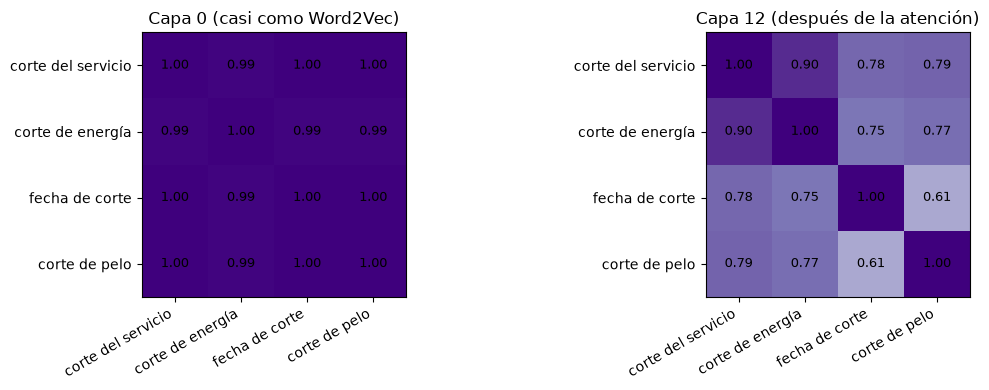

In [12]:
# ✍️ LIVE CODING — 2.2 La misma palabra "corte" en 4 contextos: vector estático vs contextual
frases = ["Me hicieron un corte del servicio sin aviso",
          "Hubo un corte de energía en todo el barrio",
          "La fecha de corte de la factura es el 15",
          "Me hice un corte de pelo nuevo"]

def vectores_de(palabra, frase):
    e = tok(frase, return_tensors="pt").to(device)
    idx = indice(tok.convert_ids_to_tokens(e["input_ids"][0]), palabra)
    with torch.no_grad():
        out = beto(**e)
    return [h[0, idx].cpu() for h in out.hidden_states]          # vector en cada capa (0 = entrada … 12 = salida)

capas = [vectores_de("corte", f) for f in frases]
estatico = torch.stack([c[0] for c in capas]); contextual = torch.stack([c[-1] for c in capas])
sim = lambda X: F.cosine_similarity(X.unsqueeze(1), X.unsqueeze(0), dim=-1).numpy()

etiquetas = ["corte del servicio", "corte de energía", "fecha de corte", "corte de pelo"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, M_, t in zip(ax, [sim(estatico), sim(contextual)], ["Capa 0 (casi como Word2Vec)", "Capa 12 (después de la atención)"]):
    im = a.imshow(M_, cmap="Purples", vmin=0.3, vmax=1); a.set_title(t)
    a.set_xticks(range(4)); a.set_xticklabels(etiquetas, rotation=30, ha="right"); a.set_yticks(range(4)); a.set_yticklabels(etiquetas)
    for i in range(4):
        for j in range(4): a.text(j, i, f"{M_[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.show()

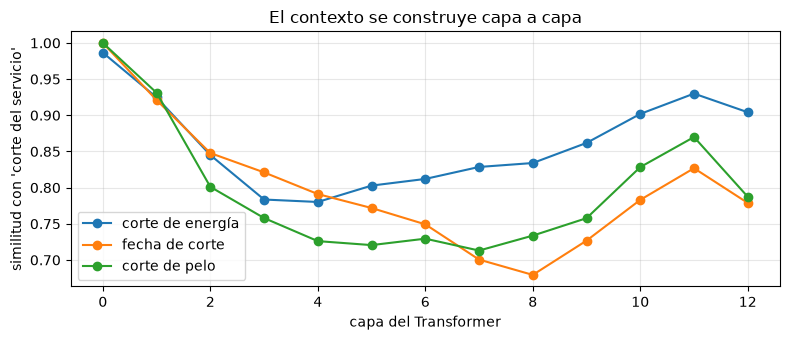

In [13]:
# ✍️ LIVE CODING — 2.3 ¿En qué capa aparece el significado? similitud con "corte del servicio" capa por capa
plt.figure(figsize=(8, 3.5))
for k, nombre in [(1, "corte de energía"), (2, "fecha de corte"), (3, "corte de pelo")]:
    plt.plot([F.cosine_similarity(capas[0][l], capas[k][l], dim=0).item() for l in range(13)], "o-", label=nombre)
plt.xlabel("capa del Transformer"); plt.ylabel("similitud con 'corte del servicio'")
plt.title("El contexto se construye capa a capa"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### 2.4 Self-attention: ¿a qué palabras "mira" cada palabra?
En cada capa, cada token calcula **cuánto atender** a los demás:
$\text{Atención}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d}}\right)V$.
Así *"pagué"* puede conectar con *"cobraron"* y el modelo "entiende" que hay una **contradicción** (señal de reclamo).

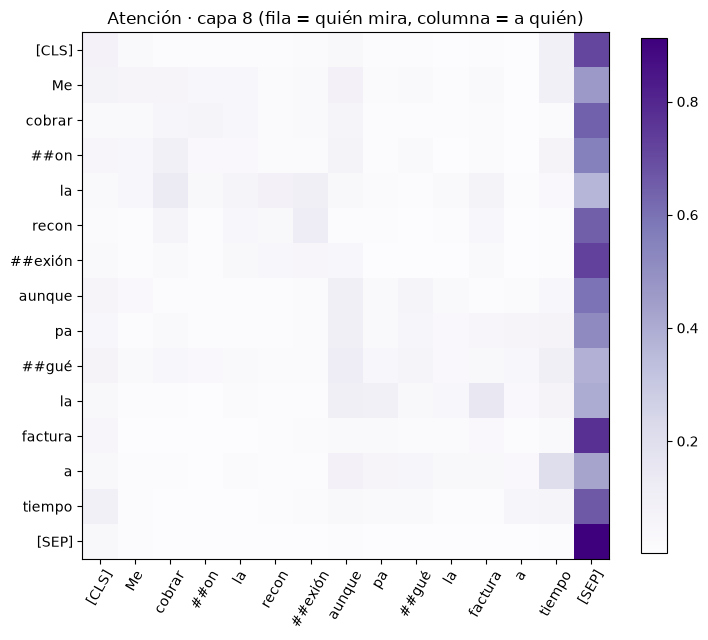

In [25]:
# ✍️ LIVE CODING — 2.4 Mapa de atención (promedio de las 12 cabezas) en una capa
frase = "Me cobraron la reconexión aunque pagué la factura a tiempo"

def mapa_atencion(frase, capa=8):
    e = tok(frase, return_tensors="pt").to(device)
    with torch.no_grad():
        att = beto(**e).attentions[capa][0].mean(0).cpu().numpy()     # [tokens, tokens]
    toks = tok.convert_ids_to_tokens(e["input_ids"][0])
    plt.figure(figsize=(7.5, 6.5)); plt.imshow(att, cmap="Purples")
    plt.xticks(range(len(toks)), toks, rotation=60); plt.yticks(range(len(toks)), toks)
    plt.title(f"Atención · capa {capa} (fila = quién mira, columna = a quién)"); plt.colorbar(fraction=.04)
    plt.tight_layout(); plt.show()
    return toks, att

toks, att = mapa_atencion(frase)

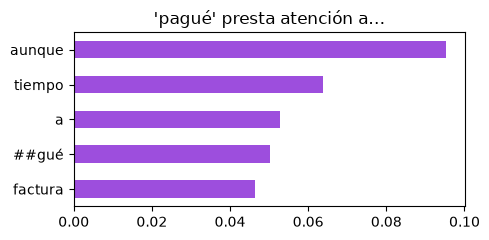

In [26]:
# ✍️ LIVE CODING — 2.5 ¿A qué mira una palabra específica?

def a_que_mira(palabra, toks=toks, att=att, top=5):
    i = indice(toks, palabra)
    orden = [j for j in np.argsort(-att[i]) if toks[j] not in ("[CLS]", "[SEP]") and j != i][:top]
    pd.Series(att[i][orden], index=[toks[j] for j in orden]).plot.barh(color="#9D4EDD", figsize=(5, 2.5),
                                                                       title=f"'{palabra}' presta atención a…")
    plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

a_que_mira("pagué")

### 2.5 Paso 5: de vectores a una decisión — ¿cómo clasifica **sin entrenarlo** (zero-shot)?
Usamos un Transformer entrenado en **NLI** (*Natural Language Inference*): dada una **premisa** y una **hipótesis**, decide si la premisa la **implica**.
```
premisa:   "Me cobraron la reconexión aunque pagué la factura a tiempo"
hipótesis: "Este mensaje es un reclamo por un cobro o una factura."   → implica: 0.91 ✅
hipótesis: "Este mensaje es una felicitación o agradecimiento."      → implica: 0.02 ❌
```
Cambiamos las etiquetas **escribiendo frases**, sin reentrenar nada. Por eso sirve el primer día, sin datos etiquetados.

In [30]:
# ✍️ LIVE CODING — 2.6 Ver el NLI "por dentro": logits de contradicción / neutral / implicación

tok_zs = AutoTokenizer.from_pretrained(MODELO_ZS)
nli = transformers.AutoModelForSequenceClassification.from_pretrained(MODELO_ZS).to(device).eval()
print(nli.config.id2label)
for h in ["Este mensaje es un reclamo por un cobro o una factura.", "Este mensaje es una felicitación o agradecimiento."]:
    e = tok_zs(frase, h, return_tensors="pt").to(device)                # premisa [SEP] hipótesis
    with torch.no_grad():
        p = F.softmax(nli(**e).logits, -1)[0].cpu().numpy()
    print(f"{h:<58} → " + " · ".join(f"{nli.config.id2label[i]}={v:.2f}" for i, v in enumerate(p)))

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 498.31it/s]


{0: 'contradiction', 1: 'neutral', 2: 'entailment'}
Este mensaje es un reclamo por un cobro o una factura.     → contradiction=0.11 · neutral=0.06 · entailment=0.83
Este mensaje es una felicitación o agradecimiento.         → contradiction=0.22 · neutral=0.78 · entailment=0.00


---
## 3. La solución paso a paso
### 3.1 ¿Qué TIPO de PQRS es? (zero-shot)
👉 **Las etiquetas son frases descriptivas**: aquí está el "prompt engineering" del zero-shot.

In [ ]:
pqrs = pqrs.head(15).copy()

In [ ]:
# ✍️ LIVE CODING — 3.1 Clasificar el tipo de todas las PQRS sin entrenar
zero_shot = pipeline("zero-shot-classification", model=MODELO_ZS, device=device)
TIPOS = {"peticion": "una solicitud de información o de un trámite",
         "queja": "una queja por una falla o por mala atención",
         "reclamo": "un reclamo para que corrijan un cobro o reparen un daño",
         "sugerencia": "una sugerencia para mejorar",
         "denuncia": "una denuncia de fraude o de un acto ilegal",
         "felicitacion": "una felicitación o un agradecimiento"}
PLANTILLA = "Este mensaje es {}."

def clasificar(textos, etiquetas):
    inv = {v: k for k, v in etiquetas.items()}
    res = zero_shot(list(textos), candidate_labels=list(etiquetas.values()), hypothesis_template=PLANTILLA)
    return [inv[r["labels"][0]] for r in res], [round(r["scores"][0], 3) for r in res]

t = time.time()
pqrs["tipo_ia"], pqrs["conf_tipo"] = clasificar(pqrs.texto, TIPOS)
print(f"⏱️ {time.time()-t:.0f}s · Exactitud IA: {accuracy_score(pqrs.tipo, pqrs.tipo_ia):.0%} "
      f"vs reglas: {accuracy_score(pqrs.tipo, pqrs.tipo_reglas):.0%}")
ConfusionMatrixDisplay.from_predictions(pqrs.tipo, pqrs.tipo_ia, cmap="Purples", xticks_rotation=45)
plt.title("Tipo de PQRS · zero-shot"); plt.tight_layout(); plt.show()

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 413.11it/s]


In [ ]:
# ✍️ LIVE CODING — 3.2 ¿Qué ÁREA lo atiende?



### 3.3 ¿Por qué decidió eso? **Explicabilidad por oclusión**
Un analista (o un juez) va a preguntar *"¿por qué la IA dijo que esto es una denuncia?"*.
Técnica simple y honesta: **quitamos una palabra a la vez** y medimos cuánto baja la probabilidad. Las palabras que más la bajan son las que **el modelo usó**.

In [ ]:
# ✍️ LIVE CODING — 3.3 Oclusión: importancia de cada palabra para la etiqueta elegida



### 3.4 ¿Qué tan URGENTE es? Modelo + conocimiento del negocio
La urgencia no es solo "qué tan enojado está". Combinamos:
- 🤖 **Sentimiento negativo** (RoBERTuito)
- 📋 **Señales de riesgo** que define el negocio (persona vulnerable, riesgo físico, riesgo legal…)
- 🔁 **Caso masivo** (lo calculamos en 3.6)

👉 Patrón profesional: **IA + reglas de negocio explicables**, no IA sola.

In [ ]:
# ✍️ LIVE CODING — 3.4 Sentimiento + señales de riesgo



### 3.5 ¿Quién, dónde, cuánto? Entidades + **anonimización** (Habeas Data)
Antes de mandar un texto a un LLM o a un tablero, se **protegen los datos personales** (Ley 1581 de 2012).
NER encuentra **personas y lugares**; las expresiones regulares encuentran **cédulas, dinero y direcciones**.

In [ ]:
# ✍️ LIVE CODING — 3.5 NER + regex → entidades y texto anonimizado



### 3.6 ¿Es un caso MASIVO? Embeddings + clustering
Si 50 usuarios reportan *"sin luz en Kennedy"* con palabras distintas, es **un solo problema**: se atiende **una vez** y se responde a todos.
Los **embeddings de oraciones** ponen cerca los textos con el mismo significado.

In [ ]:
# ✍️ LIVE CODING — 3.6 Agrupar PQRS por significado



In [ ]:
# ✍️ LIVE CODING — 3.7 Puntaje de urgencia y evaluación contra los analistas



### 3.8 Borrador de respuesta con un LLM (con datos **anonimizados** y reglas)
El LLM **no decide**: redacta un borrador con lo que ya extrajimos. El analista lo revisa y lo firma.

In [ ]:
# ✍️ LIVE CODING — 3.8 Qwen3 redacta el borrador



---
## 4. Resultado: la bandeja priorizada
Cada PQRS con: tipo, área, urgencia, señales, si es masivo y **fecha límite legal** (15 días hábiles, sin festivos).

In [ ]:
# 4.1 Fecha límite legal y bandeja ordenada (viene lista)
FESTIVOS = ["2026-11-02", "2026-11-16", "2026-12-08", "2026-12-25", "2027-01-01", "2027-01-11"]
pqrs["fecha_limite"] = pd.to_datetime(np.busday_offset(pqrs.fecha.values.astype("datetime64[D]"), 15,
                                                       roll="forward", holidays=FESTIVOS))
HOY = pd.Timestamp("2026-11-24")
pqrs["dias_habiles_restantes"] = np.busday_count(np.datetime64(HOY.date()), pqrs.fecha_limite.values.astype("datetime64[D]"),
                                                 holidays=FESTIVOS)
prioridad = {"alta": 0, "media": 1, "baja": 2}
bandeja = pqrs.assign(_p=pqrs.urgencia_ia.map(prioridad)).sort_values(["_p", "dias_habiles_restantes", "puntaje_urgencia"],
                                                                       ascending=[True, True, False])
cols = ["radicado", "urgencia_ia", "tipo_ia", "area_ia", "masivo", "senales", "dias_habiles_restantes", "texto_anonimo"]
def color(v):
    return {"alta": "background:#F3D9FA;font-weight:bold", "media": "background:#EDE7F6"}.get(v, "")
bandeja[cols].head(15).style.map(color, subset=["urgencia_ia"])

In [ ]:
# 4.2 Tablero para el jefe de PQRS
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
pd.crosstab(pqrs.area_ia, pqrs.urgencia_ia)[["alta", "media", "baja"]].plot.barh(stacked=True, ax=ax[0],
            color=["#7B2CBF", "#B197FC", "#E5DBFF"], title="Carga por área y urgencia")
pqrs.tipo_ia.value_counts().plot.pie(ax=ax[1], autopct="%1.0f%%", title="Tipo de PQRS (IA)", cmap="Purples"); ax[1].set_ylabel("")
pqrs.dias_habiles_restantes.clip(upper=15).plot.hist(bins=15, ax=ax[2], color="#9D4EDD", title="Días hábiles para vencer")
ax[2].axvline(3, color="red", ls="--"); plt.tight_layout(); plt.show()
print(f"🚨 Vencen en ≤3 días hábiles: {(pqrs.dias_habiles_restantes <= 3).sum()} · "
      f"Urgencia alta: {(pqrs.urgencia_ia == 'alta').sum()} · En casos masivos: {pqrs.masivo.sum()}")

---
## 5. ¿Cómo nos apoyamos en la IA? Impacto y riesgos

| Antes | Con el sistema |
|---|---|
| 300 h/mes leyendo y clasificando | El analista **revisa y corrige** una propuesta (~1 min por PQRS) |
| Casos graves enterrados en la cola | Bandeja ordenada por **urgencia y plazo legal** |
| 200 mensajes del mismo daño = 200 casos | **1 caso masivo**, una respuesta para todos |
| Respuestas desde cero | **Borrador** con datos del caso, revisado por un humano |
| "¿Por qué se clasificó así?" | **Explicación** palabra por palabra (oclusión) |

### Qué hace la IA y qué hace el humano
| La IA (Transformer) | El humano |
|---|---|
| Lee, entiende el contexto, propone tipo/área | Decide y corrige (cada corrección = dato para fine-tuning) |
| Detecta señales y agrupa casos | Define las reglas de negocio y los umbrales |
| Redacta un borrador | Responde de fondo y firma |

### ⚠️ Riesgos que hay que gestionar
- **Sesgos:** ¿clasifica peor a quien escribe con errores de ortografía o de manera informal? → evaluar por subgrupos.
- **Privacidad:** anonimizar antes de usar LLMs externos (Ley 1581 de 2012).
- **Alucinaciones:** el LLM nunca envía una respuesta sin revisión humana.
- **Deriva:** si cambian los productos o las tarifas, las etiquetas y el modelo se deben actualizar.

### 🏁 Reto
1. Agrega 5 PQRS nuevas "difíciles" (ironía, inglés, faltas de ortografía) y analiza qué falla.
2. Ajusta los pesos de `urgencia()` para lograr **100 % de recall en urgencia alta** sin marcar más del 40 % como alta.
3. Propón cómo usar las correcciones de los analistas para hacer **fine-tuning** de BETO cada mes.